In [576]:
# logistical/os/plotting packages
import time
import os
from copy import deepcopy
# from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# mathematics packages
from random import sample
import random
import numpy as np
# import pandas as pd
# import math
#from scipy.integrate import odeint

# define sources of randomness
#random.seed(42) #not needed but added to compare with other code templates
rng = np.random.default_rng()

In [577]:
def split_losses(population, rates, symbol):
    conc_rates = np.stack(rates, axis=1)
    total_rate = conc_rates.sum(axis=1)

    losses = np.minimum(rng.poisson(lam=total_rate*population), population)
    probabilities = np.divide(conc_rates, total_rate[..., None])  # reshaping so divide works correctly

    counts = np.zeros((len(population), conc_rates.shape[1]), dtype=int)
    for i, loss in enumerate(losses):
        if loss > 0:
            counts[i,:] = rng.multinomial(int(loss), probabilities[i,:])

    return losses, counts

def step_patches_birth_vax(x, disease_params, conn_mat, num_patches, importations=0):
    # break state up into epidemiologically relevant categories
    #x is all subpopulations
    S1=x[0:num_patches]
    S2=x[num_patches:2*num_patches]
    V=x[2*num_patches:3*num_patches]
    E=x[3*num_patches:4*num_patches]
    I=x[4*num_patches:5*num_patches]  # importations introduces noise and indicates disease arrival
    R=x[5*num_patches:6*num_patches]
    N=S1+S2+V+E+I+R

    alpha, beta, mu, noo, b, c, gamma, delta, omega, sigma = disease_params
    force_of_infection = beta*np.matmul(conn_mat, c*E+I+importations)/N

    S1_losses, S1_cats = split_losses(S1, (force_of_infection, alpha, noo), "S1")
    S1_infections, S1_vaccinations, S1_deaths = S1_cats.T
    S1_births = rng.poisson((1-b)*mu*N)

    S2_losses, S2_cats = split_losses(S2, (force_of_infection, noo), "S2")
    S2_infections, S2_deaths = S2_cats.T

    V_losses, V_cats = split_losses(V, (sigma*force_of_infection, omega, noo), "V")
    V_births = S1_births = rng.poisson(b*mu*N)
    V_infections, V_waning, V_deaths = V_cats.T

    E_losses, E_cats = split_losses(E, (gamma, noo), "E")
    E_progressions, E_deaths = E_cats.T

    I_losses, I_cats = split_losses(I, (delta, noo), "I")
    I_progressions, I_deaths = I_cats.T

    R_deaths = np.minimum(rng.poisson(lam=noo*R), R)

    S1_new = S1 + S1_births - S1_losses
    V_new = V + V_births + S1_vaccinations - V_losses
    S2_new = S2 + V_waning - S2_losses
    E_new = E + S1_infections + S2_infections + V_infections - E_losses
    I_new = I + E_progressions - I_losses
    R_new = R + I_progressions - R_deaths

    return np.concat((S1_new, S2_new, V_new, E_new, I_new, R_new))

def wastewater_detection(x, num_patches, inclusion_fracs, exposure_sensitivity, importations=0):
    S1=x[0:num_patches]
    S2=x[num_patches:2*num_patches]
    V=x[2*num_patches:3*num_patches]
    E=x[3*num_patches:4*num_patches]
    I=x[4*num_patches:5*num_patches] + importations  # importations adds noise and jump-starts outbreaks
    R=x[5*num_patches:6*num_patches]
    N=S1+S2+V+E+I+R

    cat_fracs = np.stack(((S1+S2+V+R)/N,E/N,I/N), axis=1)
    total_sampled = np.rint(inclusion_fracs*N)
    sampled_proportions = np.zeros((len(N), 3))
    for i,total_included in enumerate(total_sampled):
        sampled_proportions[i,:] = rng.multinomial(total_included, cat_fracs[i,:])/total_included

    fraction_shedding = (exposure_sensitivity*sampled_proportions[:,1]+sampled_proportions[:,2])

    return fraction_shedding

def clinical_surveillance(x, num_patches, healthcare_prob, background_rash_rate, test_sens_spec, importations=0):
    S1=x[0:num_patches]
    S2=x[num_patches:2*num_patches]
    V=x[2*num_patches:3*num_patches]
    E=x[3*num_patches:4*num_patches]
    I=x[4*num_patches:5*num_patches] + importations  # importations adds noise and jump-starts outbreaks
    R=x[5*num_patches:6*num_patches]
    N=S1+S2+V+E+I+R

    background_febrile_rash_cases = rng.poisson(lam=N*background_rash_rate)
    test_true_pos, test_true_neg = test_sens_spec

    total_rash = background_febrile_rash_cases+I
    cat_totals = np.stack((I, background_febrile_rash_cases), axis=1).astype(int)
    total_sampled = np.rint(healthcare_prob*total_rash).astype(int)
    sampled_measles = np.zeros(len(N))
    for i,total_included in enumerate(total_sampled):
        included_cases = rng.multivariate_hypergeometric(cat_totals[i,:], total_included)
        sampled_measles[i] = included_cases[0]*test_true_pos + included_cases[1]*(1-test_true_neg)

    return sampled_measles/N  # return as a percentage of population

def find_outbreak_day(example_series, incident_floor, cons_days, cumulative_floor):
    alerts = []
    for j in range(0,len(example_series)):
        alerts.append(np.all(example_series[max(j+1-cons_days,0):j+1]>=incident_floor) and cumulative_example[j]>=cumulative_floor)

    true_indices = np.flatnonzero(alerts)
    outbreak_index = true_indices[0] if true_indices.size else None
    return outbreak_index

In [578]:
num_patches = 50
num_days = 500
alpha = 0.0*np.ones(num_patches)  # 0.86
sia_alpha = 0.05
beta = 2.12*np.ones(num_patches)
b=0.71*np.ones(num_patches)  # Cameroon
gamma = 0.1*np.ones(num_patches)
delta = 0.125*np.ones(num_patches)
c = 0*np.ones(num_patches)
mu = 0.00007397*np.ones(num_patches)
noo = 0.00007397*np.ones(num_patches)  # if noo is not equal to mu, then this R_0 is incorrect. Just for diagnostic purposes
omega = 0.0*np.ones(num_patches)
sigma = 0.0*np.ones(num_patches)
n_people = 3000*np.ones(num_patches)
background_rash_rate = 0.005

# seasonal variation measles
period = 365
start_day = 0
variation = 0.2

S_1_star = (1-b)*mu/(alpha+noo)
V_star = (b*mu+alpha*S_1_star)/(omega+noo)
S_2_star = omega/noo*V_star
frac_adjusted = S_1_star + S_2_star + sigma*V_star
R_0 = (beta*frac_adjusted*(c*(noo+delta)+gamma)/((noo+gamma)*(noo+delta)))[0]
print(f"Fixed population R_0: {R_0:.3f}")
print(f"S1: {(S_1_star*n_people)[0]} S2: {(S_2_star*n_people)[0]} V: {(V_star*n_people)[0]}")

importations = np.zeros(num_patches)  # this will hold temporary cases that introduce noise into the system and jump-start outbreaks
importation_rate = 0.01*np.ones(num_patches)  # a daily importation rate
# importation_rate = np.zeros(num_patches)
# start_patch = 5
# importation_rate[start_patch] = 0.01
# importation_rate = 1.06*mu*R_0/np.sqrt(n_people)
importation_departure = 0.1*np.ones(num_patches)
importation_history = np.zeros((num_days, num_patches))

disease_params_static = [alpha, beta, mu, noo, b, c, gamma, delta, omega, sigma]
disease_params = deepcopy(disease_params_static)
ic = np.zeros(num_patches*6)
ic[0:num_patches] = np.rint(n_people*S_1_star)
ic[num_patches:2*num_patches] = np.rint(n_people*S_2_star)
ic[2*num_patches:3*num_patches] = np.rint(n_people*V_star)

Fixed population R_0: 4.912
S1: 870.0000000000001 S2: 0.0 V: 2130.0


Text(0.5, 1.0, 'Adjacency matrix for subpopulations')

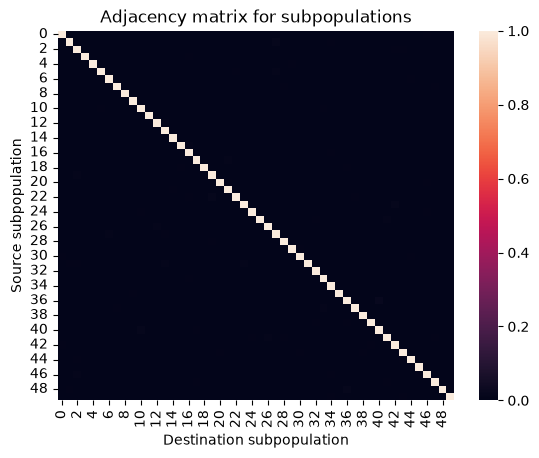

In [579]:
conn_mat = np.eye(num_patches)
for source in range(0, num_patches):
    for k in range(0,5):
        destination = np.random.randint(0, num_patches)
        if source != destination:
            conn_mat[source,destination] = rng.beta(1,299)

ax = plt.axes()
sns.heatmap(conn_mat, ax=ax)
ax.set_xlabel("Destination subpopulation")
ax.set_ylabel("Source subpopulation")
ax.set_title("Adjacency matrix for subpopulations")

In [ ]:
# surveillance accuracy characteristics
inclusion_fracs = 0.9
exposure_sensitivity = 1
healthcare_prob = 0.2
test_sens_spec = [0.8,1]

# wastewater surveillance thresholds
incident_floor = 0.005
cons_days = 3
cumulative_floor = 0.0
sample_delay = 0
waste_sampling_frequency = 7
waste_threshold = 0.001

# clinical surveillance thresholds
clin_floor = 0.01
clin_cons_days = 5
clin_cum_floor = 0
clin_delay = 0

# to hold results of simulation
results = np.zeros((num_days, num_patches*6))
results[0,:] = ic
empirical_shedding = np.zeros((num_days, num_patches))
empirical_clinical = np.zeros((num_days, num_patches))
exact_shedding = np.zeros((num_days, num_patches))
exact_shedding[0,:] = (ic[4*num_patches:5*num_patches] + exposure_sensitivity*ic[3*num_patches:4*num_patches])/n_people
trigger_intervention = np.array([[False for _ in range(0, num_patches)] for _ in range(0,num_days)])

for i in range(1,num_days):
    seasonal_beta = beta*((1-variation)+variation*(np.sin(2*np.pi*(i+start_day)/period)))
    disease_params[1] = seasonal_beta  # replace beta with seasonal version
    importations = np.rint(0, importations-rng.poisson(lam=importations*importation_departure))
    importations += rng.poisson(lam=importation_rate)
    importation_history[i,:] = deepcopy(importations)

    results[i,:] = step_patches_birth_vax(results[i-1,:], disease_params, conn_mat, num_patches, importations=importations)
    #exact_shedding[i,:] = (importations+results[i,4*num_patches:5*num_patches] + exposure_sensitivity*results[i,3*num_patches:4*num_patches])/n_people
    empirical_shedding[i,:] = wastewater_detection(results[i,:], num_patches, inclusion_fracs, exposure_sensitivity, importations=importations)
    empirical_clinical[i,:] = clinical_surveillance(results[i,:], num_patches, healthcare_prob, background_rash_rate, test_sens_spec, importations=importations)

    if i % waste_sampling_frequency == 0:
        trigger_intervention[min(i+sample_delay, num_days),:] = (empirical_shedding[i,:] >= waste_threshold)

Text(0, 0.5, 'Infections')

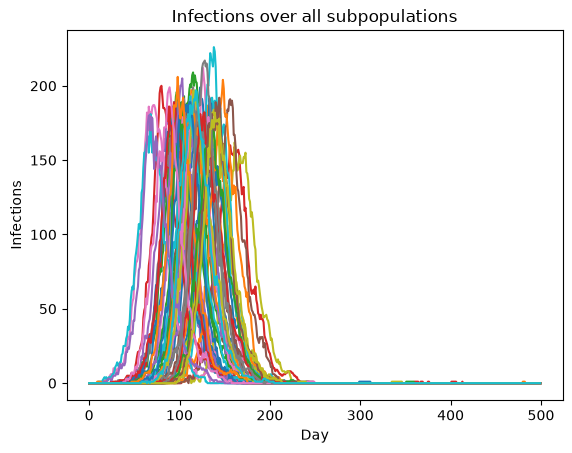

In [581]:
for j in range(0,num_patches):
    plt.plot(list(range(0,num_days)), results[:,j+4*num_patches])
plt.title("Infections over all subpopulations")
plt.xlabel("Day")
plt.ylabel("Infections")
#plt.ylim([0, 10])
#plt.xlim([75,150])

Text(0, 0.5, '#')

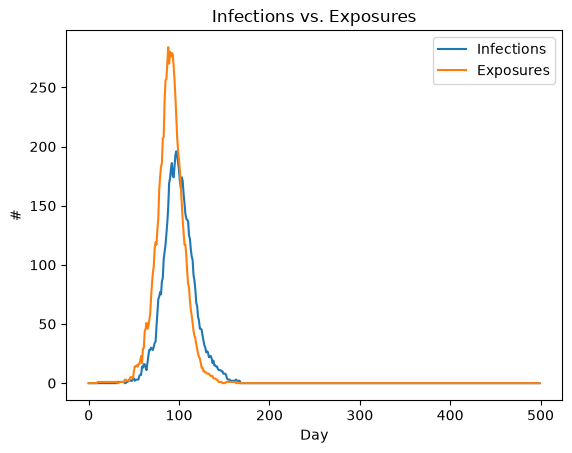

In [582]:
demo_patch=12
plt.plot(list(range(0,num_days)), results[:,demo_patch+4*num_patches], label="Infections")
plt.plot(list(range(0,num_days)), results[:,demo_patch+3*num_patches], label="Exposures")
plt.legend()
plt.title("Infections vs. Exposures")
plt.xlabel("Day")
plt.ylabel("#")
#plt.ylim([0, 10])
#plt.xlim([75,150])

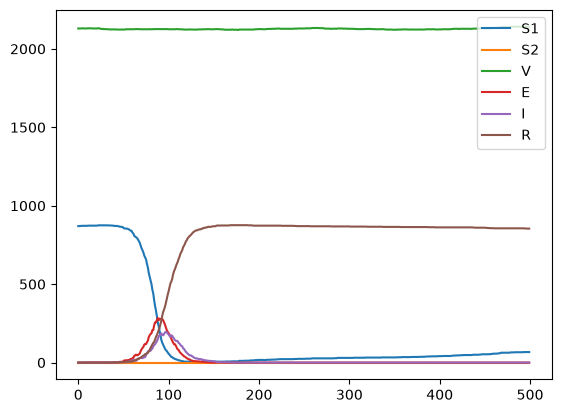

In [583]:
syms = ["S1", "S2", "V", "E", "I", "R"]
for k in range(0,6):
    y_vals = results[:,demo_patch+k*num_patches]
    if syms[k] == "I":
        y_vals += importation_history[:,12]
    plt.plot(list(range(0,num_days)), y_vals, label=syms[k])
plt.legend()
plt.show()

In [584]:
print(np.max(importation_history))

2.0


Initial day: 59


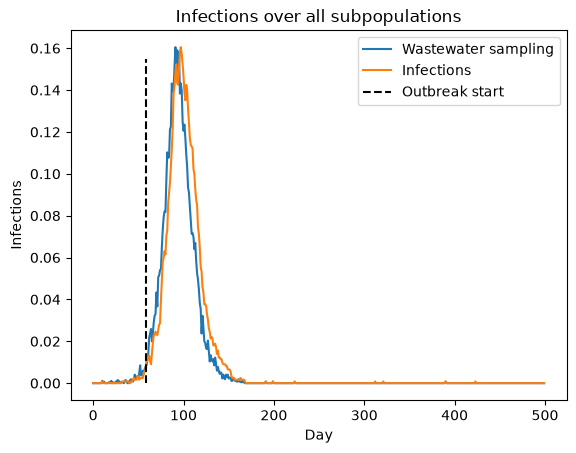

In [585]:
demo_patch = 12
example_series = empirical_shedding[:,demo_patch]
infections = results[:,4*num_patches+demo_patch]/(np.max(results[:,4*num_patches+demo_patch]))*np.max(example_series)
cumulative_example = np.cumsum(example_series)
alerts = []


outbreak_index = find_outbreak_day(example_series, incident_floor, cons_days, cumulative_floor)
print(f"Initial day: {outbreak_index}")

if sample_delay > 0:
    hypothetical_sampling = np.zeros(num_days)
    hypothetical_sampling[sample_delay:] = empirical_shedding[:-sample_delay, demo_patch]
else:
    hypothetical_sampling = empirical_shedding[:,demo_patch]

#plt.plot(list(range(0,num_days)), empirical_shedding[:,demo_patch], label="Wastewater sampling")
plt.plot(list(range(0,num_days)), hypothetical_sampling, label="Wastewater sampling")
#plt.plot(list(range(0,num_days)), exact_shedding[:,demo_patch], label="True shedding")
plt.plot(list(range(0,num_days)), infections, label="Infections")
plt.vlines(outbreak_index, 0, max(exact_shedding[:,demo_patch]), colors="black", linestyles="dashed", label="Outbreak start")
plt.title("Infections over all subpopulations")
plt.xlabel("Day")
plt.ylabel("Infections")
plt.legend()

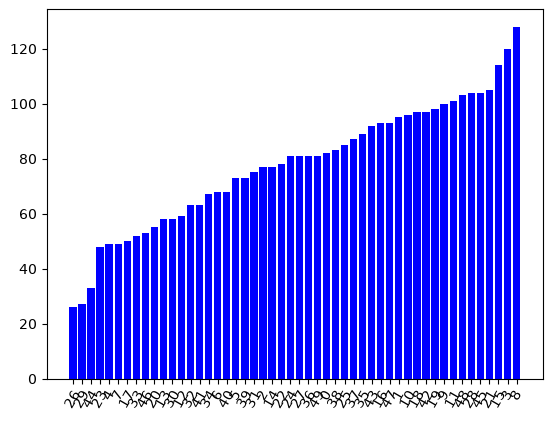

In [586]:
outbreak_days = []
colors = []
for j in range(0, num_patches):
    outbreak_days.append(find_outbreak_day(empirical_shedding[:,j], incident_floor, cons_days, cumulative_floor))
    if outbreak_days[j] < len(empirical_shedding[:,j]):
        colors.append("blue")
    else:
        colors.append("red")

order = sorted(range(len(outbreak_days)), key=outbreak_days.__getitem__)
days_sorted = [outbreak_days[i] for i in order]
colors_sorted = [colors[i] for i in order]

plt.bar(list(range(0,num_patches)), days_sorted, color=colors_sorted, tick_label=order)
plt.xticks(rotation=60)
plt.show()